# 🌸 Image Labelling Bunga (Flowers)
Notebook ini mengikuti alur tutorial **Image Labelling Process** (labelImg → format YOLO), tetapi disesuaikan agar berjalan di Google Colab.

**Topik:** Flowers · **5 kelas** · **50 gambar per kelas** (total 250 gambar)
**Penyimpanan:** Google Drive

| Nama | NIM |
|---|---|
| Putra Alfa Juliano Bunga | 672024212 |
| Nathan Elden Mandeij | 672024221 |
| Kristopher Sardo Sihotang | 672024221 |

## Mount Google Drive

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Konfigurasi folder & kelas (predefined_classes.txt)

In [10]:
import os

BASE_DIR = '/content/drive/MyDrive/Flower_Labeling'
IMG_DIR  = f'{BASE_DIR}/images'
LBL_DIR  = f'{BASE_DIR}/labels'
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(LBL_DIR, exist_ok=True)

CLASSES = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']   # 5 kelas
IMAGES_PER_CLASS = 50

# predefined_classes.txt (seperti di tutorial) + classes.txt (dipakai format YOLO)
for fname in ['predefined_classes.txt', 'classes.txt']:
    with open(f'{LBL_DIR}/{fname}', 'w') as f:
        f.write('\n'.join(CLASSES) + '\n')

print('Folder gambar :', IMG_DIR)
print('Folder label  :', LBL_DIR)
print('Kelas         :', CLASSES)

Folder gambar : /content/drive/MyDrive/Flower_Labeling/images
Folder label  : /content/drive/MyDrive/Flower_Labeling/labels
Kelas         : ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


## Download gambar bunga (open source) → simpan ke Google Drive
Sumber: **TensorFlow Flower Photos** (dataset terbuka, 5 kelas bunga). Dari tiap kelas diambil 50 gambar acak, lalu disalin ke Drive.

In [11]:
import urllib.request, tarfile, random, shutil, glob

URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
TGZ = '/content/flower_photos.tgz'

if not os.path.exists(TGZ):
    print('Mengunduh dataset (~220 MB)...')
    urllib.request.urlretrieve(URL, TGZ)
if not os.path.exists('/content/flower_photos'):
    print('Mengekstrak...')
    with tarfile.open(TGZ) as t:
        t.extractall('/content')

random.seed(42)
for cls in CLASSES:
    files  = sorted(glob.glob(f'/content/flower_photos/{cls}/*.jpg'))
    chosen = random.sample(files, IMAGES_PER_CLASS)
    for i, src in enumerate(chosen, 1):
        dst = f'{IMG_DIR}/{cls}_{i:03d}.jpg'
        if not os.path.exists(dst):
            shutil.copy(src, dst)
    print(f'{cls:12s} -> {IMAGES_PER_CLASS} gambar disimpan')

print('\nTotal gambar di Drive:', len([f for f in os.listdir(IMG_DIR) if f.endswith('.jpg')]))

daisy        -> 50 gambar disimpan
dandelion    -> 50 gambar disimpan
roses        -> 50 gambar disimpan
sunflowers   -> 50 gambar disimpan
tulips       -> 50 gambar disimpan

Total gambar di Drive: 250


## Cek jumlah gambar per kelas

In [12]:
from collections import Counter
files = sorted(f for f in os.listdir(IMG_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')))
cnt = Counter(f.rsplit('_', 1)[0] for f in files)
for c in CLASSES:
    print(f'{c:12s}: {cnt[c]} gambar')
print('Total       :', len(files))

daisy       : 50 gambar
dandelion   : 50 gambar
roses       : 50 gambar
sunflowers  : 50 gambar
tulips      : 50 gambar
Total       : 250


### Tool Image Labelling (pengganti labelImg)
**Cara pakai**
1. Tekan & seret mouse di atas gambar untuk membuat kotak (RectBox) pada bunga.
2. Kelas otomatis terisi dari nama file (centang *Use default label*), atau pilih manual lewat dropdown / tombol angka **1–5**.
3. **Next / Prev** menyimpan otomatis. Shortcut: `D` = next, `A` = prev, `Z` = undo, `S` = save.
4. Hasil tersimpan ke `labels/<nama_gambar>.txt` di Google Drive, format YOLO: `class x_center y_center width height` (ternormalisasi).

Tool otomatis mulai dari gambar pertama yang belum dilabeli, jadi bisa dilanjutkan kapan saja.

In [17]:
os.remove(f'{LBL_DIR}/daisy_001.txt')

In [18]:
import json, base64, io
from PIL import Image, ImageOps
from IPython.display import HTML, display, JSON
from google.colab import output

IMAGE_FILES = sorted(f for f in os.listdir(IMG_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')))

def _lbl_path(name):
    return os.path.join(LBL_DIR, os.path.splitext(name)[0] + '.txt')

def lb_get(idx):
    idx = max(0, min(int(idx), len(IMAGE_FILES) - 1))
    name = IMAGE_FILES[idx]
    im = ImageOps.exif_transpose(Image.open(os.path.join(IMG_DIR, name))).convert('RGB')
    im.thumbnail((800, 800))
    buf = io.BytesIO()
    im.save(buf, 'JPEG', quality=85)
    data = 'data:image/jpeg;base64,' + base64.b64encode(buf.getvalue()).decode()

    boxes, p = [], _lbl_path(name)
    if os.path.exists(p):
        for line in open(p):
            parts = line.split()
            if len(parts) == 5:
                boxes.append([int(parts[0])] + [float(x) for x in parts[1:]])

    default_cls = -1
    for i, c in enumerate(CLASSES):
        if name.startswith(c + '_'):
            default_cls = i
    labeled = sum(os.path.exists(_lbl_path(f)) for f in IMAGE_FILES)
    return JSON({'idx': idx, 'name': name, 'total': len(IMAGE_FILES), 'img': data,
                 'boxes': boxes, 'default_cls': default_cls, 'labeled': labeled})

def lb_save(name, boxes_json):
    boxes = json.loads(boxes_json)
    p = _lbl_path(name)
    if boxes:
        with open(p, 'w') as f:
            for c, xc, yc, w, h in boxes:
                f.write(f'{int(c)} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n')
    elif os.path.exists(p):
        os.remove(p)
    return JSON({'ok': True, 'n': len(boxes)})

output.register_callback('labeler.get', lb_get)
output.register_callback('labeler.save', lb_save)

# mulai dari gambar pertama yang belum dilabeli
START = next((i for i, f in enumerate(IMAGE_FILES) if not os.path.exists(_lbl_path(f))), 0)

HTML_UI = '''
<style>
 #lb{font-family:Arial,sans-serif}
 #lb button{margin:2px;padding:6px 10px;cursor:pointer}
 #lbc{border:2px solid #444;cursor:crosshair;max-width:100%}
</style>
<div id="lb">
 <div>
  <button id="lbPrev">⬅ Prev (A)</button>
  <button id="lbNext">Next (D) ➡</button>
  <button id="lbSave">💾 Save (S)</button>
  <button id="lbUndo">↩ Undo (Z)</button>
  <button id="lbClear">🗑 Clear</button>
  &nbsp; Class: <select id="lbCls"></select>
  <label><input type="checkbox" id="lbDef" checked> Use default label</label>
  &nbsp; Go to #: <input id="lbGo" type="number" min="1" style="width:65px"><button id="lbGoBtn">Go</button>
 </div>
 <div id="lbInfo" style="margin:6px 0;font-weight:bold"></div>
 <canvas id="lbc" tabindex="0"></canvas>
</div>
<script>
(function(){
 const CLASSES = __CLASSES__;
 const COLORS = ['#ff4d4d','#ffb300','#e040fb','#ffee00','#00e5ff','#76ff03'];
 let idx = __START__, cur = null, boxes = [], drawing = false, sx=0, sy=0, mx=0, my=0;
 const img = new Image();
 const cv = document.getElementById('lbc'), ctx = cv.getContext('2d');
 const sel = document.getElementById('lbCls'), def = document.getElementById('lbDef');
 const info = document.getElementById('lbInfo');
 CLASSES.forEach((c,i)=>{ const o=document.createElement('option'); o.value=i; o.text=(i+1)+' - '+c; sel.appendChild(o); });

 async function call(fn, args){
   const r = await google.colab.kernel.invokeFunction(fn, args, {});
   return r.data['application/json'];
 }
 function redraw(){
   ctx.clearRect(0,0,cv.width,cv.height);
   ctx.drawImage(img,0,0,cv.width,cv.height);
   ctx.lineWidth = 3; ctx.font = 'bold 16px Arial';
   boxes.forEach(b=>{
     const [c,xc,yc,w,h] = b;
     const x=(xc-w/2)*cv.width, y=(yc-h/2)*cv.height, bw=w*cv.width, bh=h*cv.height;
     ctx.strokeStyle = COLORS[c%COLORS.length]; ctx.strokeRect(x,y,bw,bh);
     ctx.fillStyle = ctx.strokeStyle; ctx.fillRect(x,y-20,ctx.measureText(CLASSES[c]).width+8,20);
     ctx.fillStyle = '#000'; ctx.fillText(CLASSES[c], x+4, y-4);
   });
   if(drawing){
     ctx.strokeStyle = COLORS[sel.value%COLORS.length]; ctx.setLineDash([6,4]);
     ctx.strokeRect(sx,sy,mx-sx,my-sy); ctx.setLineDash([]);
   }
 }
 function updateInfo(extra){
   info.textContent = 'Image ' + (idx+1) + ' / ' + cur.total + '  |  ' + cur.name +
     '  |  boxes: ' + boxes.length + '  |  labeled files: ' + cur.labeled + (extra ? '  |  ' + extra : '');
 }
 async function load(i){
   cur = await call('labeler.get', [i]);
   idx = cur.idx; boxes = cur.boxes.map(b=>b.slice());
   if(def.checked && cur.default_cls >= 0) sel.value = cur.default_cls;
   img.onload = ()=>{ cv.width = img.width; cv.height = img.height; redraw(); updateInfo(); };
   img.src = cur.img;
 }
 async function save(){
   const r = await call('labeler.save', [cur.name, JSON.stringify(boxes)]);
   cur.labeled = (r.n > 0 && cur.boxes.length === 0) ? cur.labeled + 1 : cur.labeled;
   cur.boxes = boxes.map(b=>b.slice());
   updateInfo('✅ saved');
 }
 async function go(i){ await save(); await load(i); }

 function pos(e){
   const r = cv.getBoundingClientRect();
   return [(e.clientX-r.left)*cv.width/r.width, (e.clientY-r.top)*cv.height/r.height];
 }
 cv.addEventListener('mousedown', e=>{ [sx,sy]=pos(e); mx=sx; my=sy; drawing=true; });
 cv.addEventListener('mousemove', e=>{ if(drawing){ [mx,my]=pos(e); redraw(); } });
 window.addEventListener('mouseup', e=>{
   if(!drawing) return; drawing = false;
   const x1=Math.max(0,Math.min(sx,mx)), x2=Math.min(cv.width,Math.max(sx,mx));
   const y1=Math.max(0,Math.min(sy,my)), y2=Math.min(cv.height,Math.max(sy,my));
   if(x2-x1>5 && y2-y1>5){
     boxes.push([parseInt(sel.value),(x1+x2)/2/cv.width,(y1+y2)/2/cv.height,(x2-x1)/cv.width,(y2-y1)/cv.height]);
   }
   redraw(); updateInfo();
 });
 document.getElementById('lbPrev').onclick = ()=>go(idx-1);
 document.getElementById('lbNext').onclick = ()=>go(idx+1);
 document.getElementById('lbSave').onclick = save;
 document.getElementById('lbUndo').onclick = ()=>{ boxes.pop(); redraw(); updateInfo(); };
 document.getElementById('lbClear').onclick = ()=>{ boxes=[]; redraw(); updateInfo(); };
 document.getElementById('lbGoBtn').onclick = ()=>{ const v=parseInt(document.getElementById('lbGo').value); if(v>0) go(v-1); };
 document.addEventListener('keydown', e=>{
   if(e.target.tagName==='INPUT' && e.target.type==='number') return;
   const k = e.key.toLowerCase();
   if(k==='d') go(idx+1); else if(k==='a') go(idx-1);
   else if(k==='z'){ boxes.pop(); redraw(); updateInfo(); }
   else if(k==='s') save();
   else if(k>='1' && parseInt(k)<=CLASSES.length){ sel.value=parseInt(k)-1; def.checked=false; }
 });
 load(idx);
})();
</script>
'''
display(HTML(HTML_UI.replace('__CLASSES__', json.dumps(CLASSES)).replace('__START__', str(START))))

In [19]:
# Tes penyimpanan langsung dari Python (tanpa tool visual)
lb_save('daisy_001.jpg', '[[0, 0.5, 0.5, 0.3, 0.3]]')
print(os.listdir(LBL_DIR))
print(open(f'{LBL_DIR}/daisy_001.txt').read())

['predefined_classes.txt', 'classes.txt', 'daisy_001.txt', 'daisy_002.txt', 'daisy_003.txt', 'daisy_004.txt', 'daisy_005.txt', 'daisy_006.txt', 'daisy_007.txt', 'daisy_008.txt', 'daisy_009.txt', 'daisy_010.txt', 'daisy_011.txt', 'daisy_012.txt', 'daisy_013.txt', 'daisy_014.txt', 'daisy_015.txt', 'daisy_016.txt', 'daisy_017.txt', 'daisy_018.txt', 'daisy_019.txt', 'daisy_020.txt', 'daisy_021.txt', 'daisy_022.txt', 'daisy_023.txt', 'daisy_024.txt', 'daisy_025.txt', 'daisy_026.txt', 'daisy_027.txt', 'daisy_028.txt', 'daisy_029.txt', 'daisy_030.txt', 'daisy_031.txt', 'daisy_032.txt', 'daisy_033.txt', 'daisy_034.txt', 'daisy_035.txt', 'daisy_036.txt', 'daisy_037.txt', 'daisy_038.txt', 'daisy_039.txt', 'daisy_040.txt', 'daisy_041.txt', 'daisy_042.txt', 'daisy_043.txt', 'daisy_044.txt', 'daisy_045.txt', 'daisy_046.txt', 'daisy_047.txt', 'daisy_048.txt', 'daisy_049.txt', 'daisy_050.txt', 'dandelion_001.txt', 'dandelion_002.txt', 'dandelion_003.txt', 'dandelion_004.txt', 'dandelion_005.txt', 'da

## **Cek progres labeling**

In [20]:
labeled = [f for f in IMAGE_FILES if os.path.exists(os.path.join(LBL_DIR, os.path.splitext(f)[0] + '.txt'))]
print(f'Sudah dilabeli: {len(labeled)} / {len(IMAGE_FILES)}')

box_per_class = Counter()
for f in labeled:
    for line in open(os.path.join(LBL_DIR, os.path.splitext(f)[0] + '.txt')):
        box_per_class[CLASSES[int(line.split()[0])]] += 1
for c in CLASSES:
    print(f'{c:12s}: {box_per_class[c]} kotak')

belum = [f for f in IMAGE_FILES if f not in labeled]
print('\nBelum dilabeli:', belum[:10], '...' if len(belum) > 10 else '')

Sudah dilabeli: 242 / 250
daisy       : 110 kotak
dandelion   : 62 kotak
roses       : 93 kotak
sunflowers  : 148 kotak
tulips      : 159 kotak

Belum dilabeli: ['roses_013.jpg', 'roses_042.jpg', 'tulips_013.jpg', 'tulips_016.jpg', 'tulips_021.jpg', 'tulips_033.jpg', 'tulips_035.jpg', 'tulips_041.jpg'] 


## Visualisasi hasil label (verifikasi)

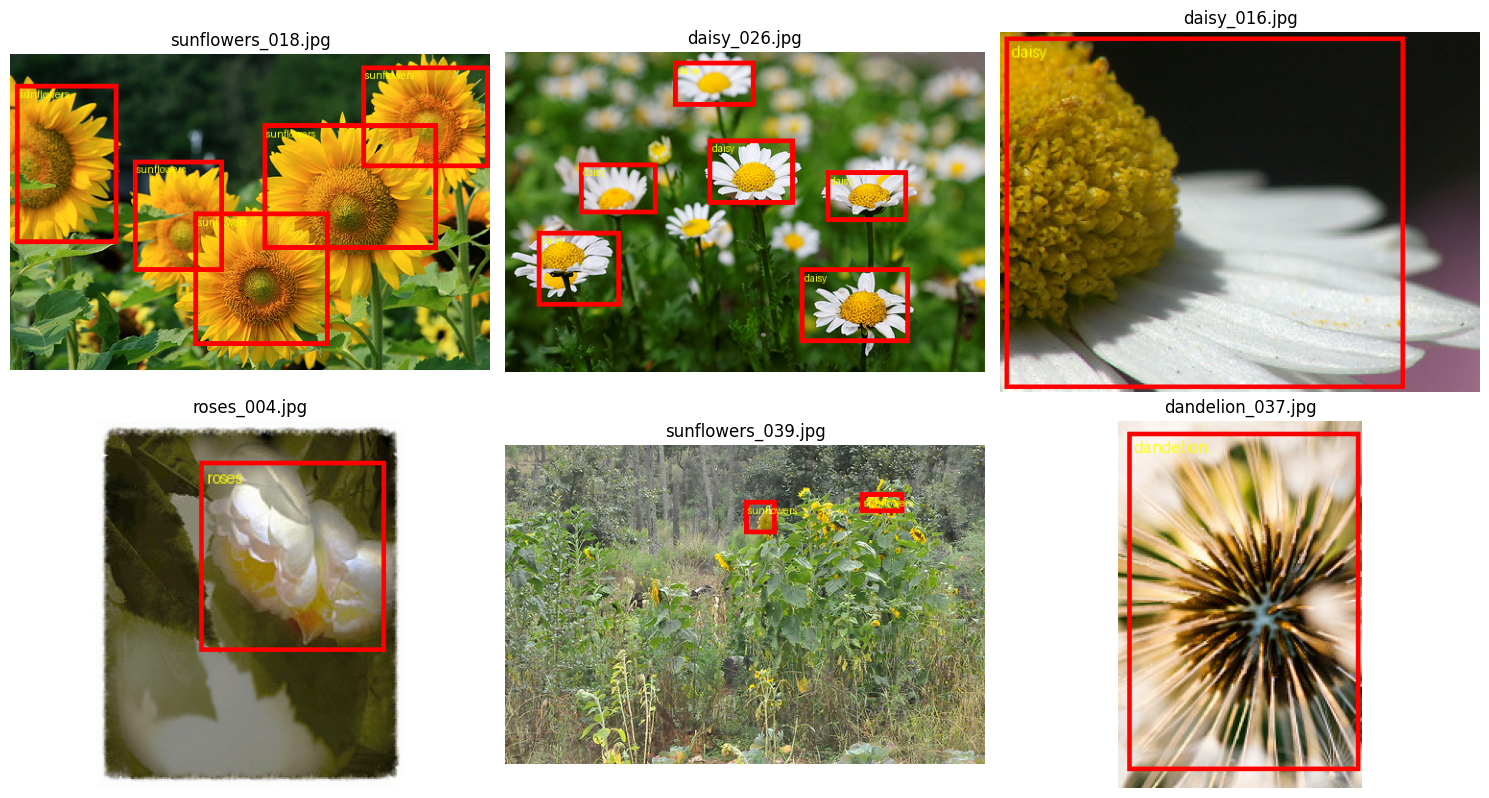

In [21]:
import matplotlib.pyplot as plt
from PIL import ImageDraw

def show_labeled(n=6):
    pick = random.sample(labeled, min(n, len(labeled)))
    if not pick:
        print('Belum ada gambar yang dilabeli.'); return
    cols = 3; rows = (len(pick) + cols - 1) // cols
    plt.figure(figsize=(5 * cols, 4 * rows))
    for k, f in enumerate(pick):
        im = ImageOps.exif_transpose(Image.open(os.path.join(IMG_DIR, f))).convert('RGB')
        W, H = im.size
        d = ImageDraw.Draw(im)
        for line in open(os.path.join(LBL_DIR, os.path.splitext(f)[0] + '.txt')):
            c, xc, yc, w, h = line.split(); c = int(c); xc, yc, w, h = map(float, (xc, yc, w, h))
            box = [(xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H]
            d.rectangle(box, outline='red', width=max(3, W // 100))
            d.text((box[0] + 4, box[1] + 4), CLASSES[c], fill='yellow')
        plt.subplot(rows, cols, k + 1); plt.imshow(im); plt.title(f); plt.axis('off')
    plt.tight_layout(); plt.show()

show_labeled(6)

##  (Opsional) Buat `data.yaml` untuk training YOLO
File ini disimpan di folder yang sama di Google Drive.

In [23]:
yaml_text = f'''path: {BASE_DIR}
train: images
val: images
nc: {len(CLASSES)}
names: {CLASSES}
'''
with open(f'{BASE_DIR}/data.yaml', 'w') as f:
    f.write(yaml_text)
print(yaml_text)
print('Tersimpan di:', f'{BASE_DIR}/data.yaml')

path: /content/drive/MyDrive/Flower_Labeling
train: images
val: images
nc: 5
names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']

Tersimpan di: /content/drive/MyDrive/Flower_Labeling/data.yaml
